# Credit Card Fraud Detection

## Objective
To build a Machine Learning model that identifies fraudulent
credit card transactions.

## Problem Type
## Supervised Learning - Binary **Classification**

## Tools
Python, NumPy, Pandas, Matplotlib, Seaborn and Scikit-learn

In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,average_precision_score,roc_auc_score


In [57]:
data = pd.read_csv('/content/creditcard[1].csv')

print(data.head())
print("Shape:", data.shape)
print(data.info())
print(data.describe())
print("Missing Values:\n", data.isnull().sum())
print("Duplicate Records:", data.duplicated().sum())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 


Transaction Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


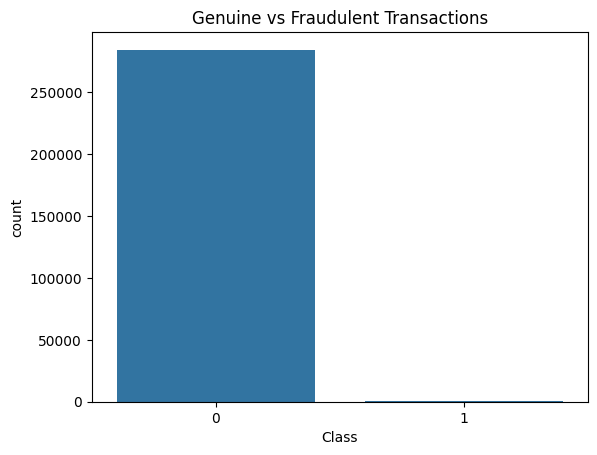

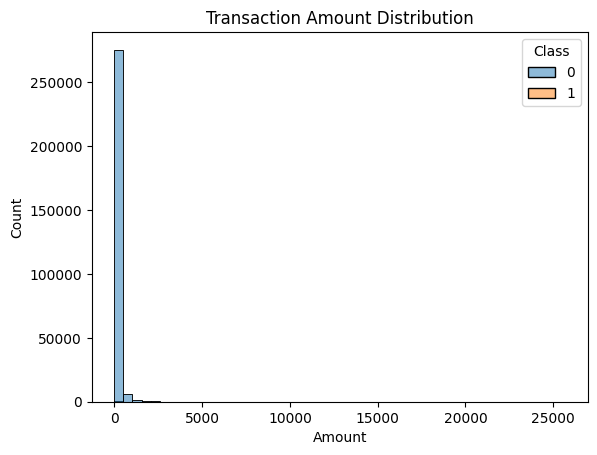

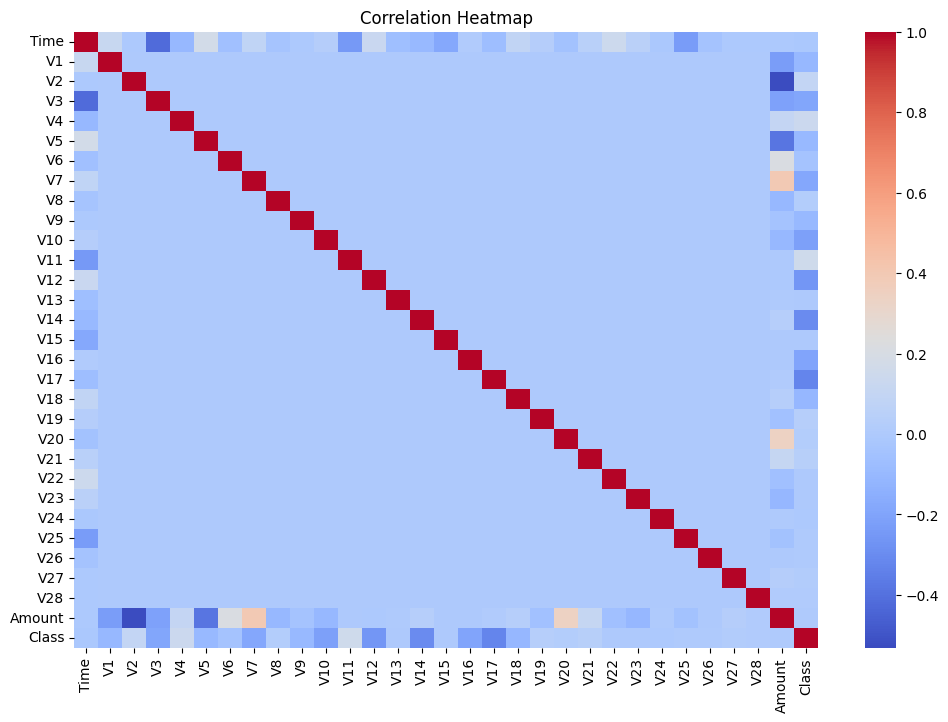

In [72]:
print("\nTransaction Distribution:")
print(data['Class'].value_counts())

sns.countplot(x='Class', data=data)
plt.title("Genuine vs Fraudulent Transactions")
plt.show()

sns.histplot(data=data, x='Amount', hue='Class',
             bins=50)
plt.title("Transaction Amount Distribution")
plt.show()

plt.figure(figsize=(12, 8))
sns.heatmap(data.corr(numeric_only=True),
            annot=False, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()



In [59]:

x = data.drop('Class', axis=1)
y = data['Class']

In [60]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [61]:
scaler = StandardScaler()

x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)



In [62]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}



In [ ]:
results = []

for name, model in models.items():
    model.fit(x_train, y_train)
    prediction = model.predict(x_test)
    accuracy = accuracy_score(y_test, prediction)
    precision = precision_score(y_test, prediction, zero_division=0)
    recall = recall_score(y_test, prediction, zero_division=0)
    f1 = f1_score(y_test, prediction, zero_division=0)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,

    })

    print("\n", name)
    print(classification_report(y_test, prediction, zero_division=0))
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, prediction))



 Logistic Regression
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.83      0.63      0.72        98

    accuracy                           1.00     56962
   macro avg       0.91      0.82      0.86     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56851    13]
 [   36    62]]

 Decision Tree
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.75      0.74      0.75        98

    accuracy                           1.00     56962
   macro avg       0.88      0.87      0.87     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56840    24]
 [   25    73]]


In [64]:
results_df = pd.DataFrame(results)

print("\nModel Comparison:")
print(results_df.to_string(index=False))


Model Comparison:
              Model  Accuracy  Precision   Recall  F1 Score  Training Time
Logistic Regression  0.999140   0.826667 0.632653  0.716763       1.368396
      Decision Tree  0.999140   0.752577 0.744898  0.748718      43.509245
      Random Forest  0.999596   0.941176 0.816327  0.874317     414.479173


In [ ]:
param = {
    'n_estimators': [50, 100],
    'max_depth': [10, 20, None]
}

random_search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=1),
    param,
    cv=3,
    scoring='average_precision',
    n_iter=3,
    random_state=42,
)
random_search.fit(x_train, y_train)
print("\nBest Parameters:")
print(random_search.best_params_)

In [66]:
final_model = random_search.best_estimator_

final_prediction = final_model.predict(x_test)

final_probabilities = final_model.predict_proba(x_test)[:, 1]

In [67]:
print("\nFINAL RANDOM FOREST RESULTS")

print("Accuracy:",
      accuracy_score(y_test, final_prediction))

print("Precision:",
      precision_score(y_test, final_prediction, zero_division=0))

print("Recall:",
      recall_score(y_test, final_prediction, zero_division=0))

print("F1 Score:",
      f1_score(y_test, final_prediction, zero_division=0))

print("Average Precision:",
      average_precision_score(y_test, final_probabilities))

print("ROC AUC:",
      roc_auc_score(y_test, final_probabilities))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, final_prediction))

print("\nClassification Report:")
print(classification_report(y_test, final_prediction, zero_division=0))


FINAL RANDOM FOREST RESULTS
Accuracy: 0.9995962220427653
Precision: 0.9411764705882353
Recall: 0.8163265306122449
F1 Score: 0.8743169398907104
Average Precision: 0.8733910547021404
ROC AUC: 0.9630272515590367

Confusion Matrix:
[[56859     5]
 [   18    80]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.94      0.82      0.87        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



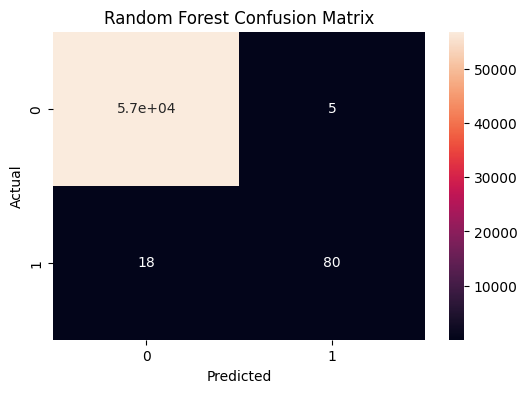

In [71]:
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_matrix(y_test, final_prediction),
    annot=True,

)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [69]:
single_obs = [[
    0.0, -1.359807, -0.072781, 2.536347,
    1.378155, -0.338321, 0.462388, 0.239599,
    0.098698, 0.363787, 0.090794, -0.551600,
    -0.617801, -0.991390, -0.311169, 1.468177,
    -0.470401, 0.207971, 0.025791, 0.403993,
    0.251412, -0.018307, 0.277838, -0.110474,
    0.066928, 0.128539, -0.189115, 0.133558,
    -0.021053, 149.62
]]

single_obs_scaled = scaler.transform(single_obs)

new_obv_pred = final_model.predict(single_obs_scaled)

print("\nNew Transaction Prediction:")

if new_obv_pred[0] == 1:
    print("Fraudulent Transaction")
else:
    print("Genuine Transaction")



New Transaction Prediction:
Genuine Transaction


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
